# Fase 2 — Preparação

**Objetivo:** transformar cada local em vetor e separar os dados, sem vazamento. As decisões usam só o treino; o período de teste entra apenas para calcular o corte e contar avaliações.

**Decisões e a evidência da Fase 1 por trás de cada uma:**

| Decisão | Evidência (`01_dados.ipynb`) |
|---|---|
| Só atributos declaráveis no vetor | Entre os 15 atributos mais comuns, 10 vêm de grupos derivados do comportamento dos clientes |
| Preço fora do vetor | Falta em 90,3% dos locais sem avaliação e em 5,0% dos mais populares |
| Categorias e atributos, não só categorias | Jaccard de categorias: 0,0878 em gostou × gostou, contra 0,0964 em não gostou × gostou |
| Validação de um ano completo | Julho tem 2,05 vezes as avaliações de fevereiro; nas cidades turísticas, 3,29 vezes |
| Relevante é nota 4 ou maior | 77,6% das avaliações antes do corte têm nota 4 ou 5 |
| Segmento de usuário novo | De 51,1% a 57,4% das avaliações futuras vêm de quem não tem histórico |
| Locais novos naturais como resultado principal do cenário 3 | Locais novos recebem de 1,8% a 2,7% das avaliações futuras, em 53 a 91 locais |

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from src.dados import GRUPOS_DECLARAVEIS, atributos_do_local
from src.divisao import calcular_cortes, dividir_temporal, eh_relevante, montar_conjuntos
from src.features import SINONIMOS, VALORES_EXCLUIDOS, VetorizadorConteudo, tokens_do_local
from src.graficos import COR_EIXO, COR_PRINCIPAL, COR_TEXTO, aplicar_estilo, eixo_br, numero_br, salvar

PASTA_PROCESSADOS = Path("data/processed")

aplicar_estilo()


def inteiro(valor):
    return f"{valor:,}".replace(",", ".")


def percentual(valor):
    return f"{valor:.1%}".replace(".", ",")


avaliacoes = pd.read_parquet(PASTA_PROCESSADOS / "avaliacoes.parquet", columns=["user_id", "gmap_id", "rating", "data"])
locais = pd.read_parquet(PASTA_PROCESSADOS / "locais.parquet")
corte_teste, corte_validacao = calcular_cortes(avaliacoes)
particoes = dividir_temporal(avaliacoes)
treino = particoes["treino"]
print(f"Avaliações do treino, antes de {corte_validacao:%d/%m/%Y}: {inteiro(len(treino))}")

Avaliações do treino, antes de 31/03/2019: 213.626


## 2.1 Representação de conteúdo

Só entra no vetor o que um local recém-cadastrado poderia informar e que não deriva do comportamento futuro.

| Bloco | Origem | Formato do token | Peso inicial |
|---|---|---|---|
| Categorias | Todas em `category`, normalizadas | `cat=pizza_restaurant` | 1 |
| Atributos declaráveis | `MISC`, grupos Service options, Accessibility, Amenities, Payments, Planning, From the business | `misc=service_options:delivery` | 1 |

**Fora do vetor:**

| O que fica fora | Motivo |
|---|---|
| Popular for, Highlights, Crowd, Atmosphere, Offerings, Dining options | Derivam do comportamento dos clientes; um local novo não os teria |
| Health & safety, Health and safety | Temporários da pandemia |
| Preço | Falta em 90,3% dos locais sem avaliação e em 5,0% dos mais populares, o que denuncia a popularidade; continua como filtro na interface |
| Cidade | É um componente próprio do modelo |
| Texto das avaliações | Um local novo não tem |
| `relative_results`, `avg_rating`, `num_of_reviews` | Coletados depois do corte |

**Vetorização:** um TF-IDF por bloco (`sublinear_tf`, normalização L2, `min_df = 2`), ponderação por bloco, concatenação e normalização L2 final, de modo que o produto escalar seja o cosseno. Tokens desconhecidos são ignorados, o que permite vetorizar um local novo. O vetorizador é sempre ajustado só com os locais do treino correspondente, e todos os locais são transformados.

A seção 1.5 mostrou que os atributos declaráveis também crescem com a popularidade (Spearman de 0,596). Por isso, os valores abaixo foram revistos um a um, usando só as avaliações do treino.

In [2]:
popularidade = locais["gmap_id"].map(treino.groupby("gmap_id").size()).fillna(0)
atributos = locais["MISC"].map(lambda misc: set(atributos_do_local(misc)))
fechados = locais["fechado_perm"].to_numpy()
valores_declaraveis = sorted({a for conjunto in atributos for a in conjunto if a.split(": ")[0] in GRUPOS_DECLARAVEIS})


def tratamento(valor):
    if valor in VALORES_EXCLUIDOS:
        return "excluído"
    if valor in SINONIMOS:
        return f"unificado em {SINONIMOS[valor]}"
    return "mantido"


linhas = []
for atributo in valores_declaraveis:
    presente = atributos.map(lambda conjunto: atributo in conjunto).to_numpy()
    grupo, valor = atributo.split(": ", 1)
    linhas.append(
        {
            "grupo": grupo,
            "valor": valor,
            "locais": int(presente.sum()),
            "% abertos": 100 * presente[~fechados].mean(),
            "% fechados": 100 * presente[fechados].mean(),
            "Spearman com popularidade": spearmanr(presente.astype(float), popularidade).statistic,
            "tratamento": tratamento(valor),
        }
    )
revisao = pd.DataFrame(linhas)
print(f"Valores declaráveis: {len(revisao)}; excluídos: {(revisao['tratamento'] == 'excluído').sum()}; "
      f"unificados: {revisao['tratamento'].str.startswith('unificado').sum()}")
print(f"Locais fechados permanentemente: {inteiro(fechados.sum())} de {inteiro(len(locais))}")
with pd.option_context("display.max_rows", None, "display.max_colwidth", 60, "display.width", 180):
    display(revisao.round(3))

Valores declaráveis: 47; excluídos: 4; unificados: 11
Locais fechados permanentemente: 205 de 1.863


,grupo,valor,locais,% abertos,% fechados,Spearman com popularidade,tratamento
0,Accessibility,Wheelchair accessible elevator,58,3.378,0.976,0.132,mantido
1,Accessibility,Wheelchair accessible entrance,1459,83.414,37.073,0.301,mantido
2,Accessibility,Wheelchair accessible parking lot,612,35.042,15.122,0.423,mantido
3,Accessibility,Wheelchair accessible restroom,599,34.439,13.659,0.422,mantido
4,Accessibility,Wheelchair accessible seating,615,35.042,16.585,0.434,mantido
5,Accessibility,Wheelchair-accessible car park,7,0.362,0.488,0.069,unificado em Wheelchair accessible parking lot
6,Accessibility,Wheelchair-accessible entrance,20,1.206,0.000,0.092,unificado em Wheelchair accessible entrance
7,Accessibility,Wheelchair-accessible lift,1,0.000,0.488,0.020,unificado em Wheelchair accessible elevator
8,Accessibility,Wheelchair-accessible seating,9,0.483,0.488,0.086,unificado em Wheelchair accessible seating
9,Accessibility,Wheelchair-accessible toilet,12,0.663,0.488,0.100,unificado em Wheelchair accessible restroom


**Decisões sobre os valores declaráveis:**

- **Excluídos por dependerem do comportamento dos clientes:** `Planning: Usually a wait` e `Planning: Quick visit`. Um local recém-cadastrado não saberia informá-los.
- **Excluídos por virem da pandemia:** `Service options: Curbside pickup` (29,0% dos abertos, contra 1,5% dos fechados) e `Service options: No-contact delivery` (9,2%, contra 0,0%). Os metadados são uma foto de 2021, e o treino termina em 2019; a presença desses valores indica sobretudo que o local continuava aberto na coleta.
- **Unificadas 11 grafias da mesma ideia**, como `Takeaway` em `Takeout` e `Toilets` em `Restroom`, que fragmentavam o vocabulário.
- **Mantidos, com limitação declarada:** `Takeout` (85,4% dos abertos × 27,8% dos fechados), `Dine-in` (72,3% × 25,9%) e os de acessibilidade têm assimetria parecida. São declaráveis e não são específicos da pandemia, então continuam. Como locais fechados não são recomendados, o efeito atinge sobretudo os perfis de quem os avaliou.
- **Mantidos sem ajuste:** `Good for kids`, `LGBTQ friendly` e `Transgender safespace` seguem o critério do grupo; um local poderia declará-los.

In [3]:
locais_treino = locais[locais["gmap_id"].isin(treino["gmap_id"])]
vetorizador = VetorizadorConteudo().fit(locais_treino)
matriz = vetorizador.transform(locais)
nomes = vetorizador.nomes_features()
normas = np.sqrt(np.asarray(matriz.multiply(matriz).sum(axis=1)).ravel())
proibidos = [nome for nome in nomes if any(f":{valor.lower().replace(' ', '_')}" in nome for valor in VALORES_EXCLUIDOS)]

print(f"Locais usados no ajuste: {inteiro(len(locais_treino))} de {inteiro(len(locais))}")
print(f"Matriz: {inteiro(matriz.shape[0])} locais × {inteiro(matriz.shape[1])} tokens")
print(f"Tokens de categorias: {inteiro(sum(nome.startswith('cat=') for nome in nomes))}")
print(f"Tokens de atributos: {inteiro(sum(nome.startswith('misc=') for nome in nomes))}")
print(f"Locais com vetor vazio: {inteiro((normas == 0).sum())}")
print(f"Normas dos demais iguais a 1: {bool(np.allclose(normas[normas > 0], 1))}")
print(f"Tokens de valores excluídos: {len(proibidos)}")
locais.loc[normas == 0, ["name", "category", "cidade", "fechado_perm"]]

Locais usados no ajuste: 1.647 de 1.863
Matriz: 1.863 locais × 167 tokens
Tokens de categorias: 136
Tokens de atributos: 31
Locais com vetor vazio: 1
Normas dos demais iguais a 1: True
Tokens de valores excluídos: 0


,name,category,cidade,fechado_perm
387,Gillette Cheese House,[Food],Gillette,False


## 2.2 Divisão temporal

A divisão respeita o tempo: o modelo só aprende com o passado e é medido no futuro, como aconteceria em produção.

- **`corte_teste`:** quantil 80% das datas de todas as avaliações. `treino_total` fica antes; `teste`, a partir dele.
- **`corte_validacao`:** `corte_teste` menos exatamente um ano, para a validação cobrir todas as estações. `treino` fica antes; `validacao`, entre os dois.
- **Hiperparâmetros:** treinar em `treino` e medir em `validacao`.
- **Modelo final:** reajustar em `treino_total` e medir uma única vez em `teste`.
- **Relevante, ou convertido:** nota 4 ou maior.

In [4]:
MINIMO_TREINO = 150_000

linhas_particoes = []
for nome in ["treino", "validacao", "treino_total", "teste"]:
    particao = particoes[nome]
    linhas_particoes.append(
        {
            "partição": nome,
            "início": f"{particao['data'].min():%d/%m/%Y}",
            "fim": f"{particao['data'].max():%d/%m/%Y}",
            "avaliações": inteiro(len(particao)),
            "% da base": percentual(len(particao) / len(avaliacoes)),
            "usuários": inteiro(particao["user_id"].nunique()),
            "locais": inteiro(particao["gmap_id"].nunique()),
            # O teste não recebe nenhuma medida ligada às notas antes da Fase 4.
            "% relevantes": "" if nome == "teste" else percentual(eh_relevante(particao["rating"]).mean()),
        }
    )

print(f"Corte de teste: {corte_teste:%d/%m/%Y %H:%M}")
print(f"Corte de validação: {corte_validacao:%d/%m/%Y %H:%M}")
print(f"Treino com ao menos {inteiro(MINIMO_TREINO)} avaliações: {len(treino) >= MINIMO_TREINO}")
print(f"Contagens fecham: {len(particoes['treino']) + len(particoes['validacao']) == len(particoes['treino_total'])} e "
      f"{len(particoes['treino_total']) + len(particoes['teste']) == len(avaliacoes)}")
print(f"Datas sem sobreposição: {particoes['treino']['data'].max() < particoes['validacao']['data'].min() and particoes['validacao']['data'].max() < particoes['teste']['data'].min()}")
pd.DataFrame(linhas_particoes)

Corte de teste: 31/03/2020 22:50
Corte de validação: 31/03/2019 22:50
Treino com ao menos 150.000 avaliações: True
Contagens fecham: True e True
Datas sem sobreposição: True


,partição,início,fim,avaliações,% da base,usuários,locais,% relevantes
0,treino,27/03/2008,31/03/2019,213.626,"49,7%",95.365,1.647,"77,1%"
1,validacao,31/03/2019,31/03/2020,130.071,"30,3%",59.543,1.602,"78,5%"
2,treino_total,27/03/2008,31/03/2020,343.697,"80,0%",140.895,1.760,"77,6%"
3,teste,31/03/2020,04/09/2021,85.925,"20,0%",46.278,1.602,


In [5]:
NOMES_MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]


def por_mes(tabela):
    contagem = tabela.groupby(tabela["data"].dt.to_period("M")).size()
    return pd.DataFrame(
        {"mês": [f"{NOMES_MESES[periodo.month - 1]}/{periodo.year}" for periodo in contagem.index], "avaliações": contagem.values}
    )


with pd.option_context("display.max_rows", None):
    print("Validação, mês a mês:")
    display(por_mes(particoes["validacao"]))
    print("Teste, só a contagem de avaliações, mês a mês:")
    display(por_mes(particoes["teste"]))

teste = particoes["teste"]
primeiro_ano = teste["data"] < corte_teste + pd.DateOffset(years=1)
fim_da_coleta = teste["data"] >= pd.Timestamp("2021-06-01")
print(f"Teste no primeiro ano (pandemia): {inteiro(primeiro_ano.sum())} ({percentual(primeiro_ano.mean())})")
print(f"Teste depois do primeiro ano: {inteiro((~primeiro_ano).sum())} ({percentual((~primeiro_ano).mean())})")
print(f"Teste a partir de junho de 2021: {inteiro(fim_da_coleta.sum())} ({percentual(fim_da_coleta.mean())})")

Validação, mês a mês:


,mês,avaliações
0,mar/2019,20
1,abr/2019,9776
2,mai/2019,11901
3,jun/2019,14552
4,jul/2019,15956
5,ago/2019,15980
6,set/2019,12710
7,out/2019,10099
8,nov/2019,8368
9,dez/2019,7297


Teste, só a contagem de avaliações, mês a mês:


,mês,avaliações
0,mar/2020,1
1,abr/2020,906
2,mai/2020,3448
3,jun/2020,6640
4,jul/2020,9088
5,ago/2020,9411
6,set/2020,8992
7,out/2020,7419
8,nov/2020,5035
9,dez/2020,4818


Teste no primeiro ano (pandemia): 74.081 (86,2%)
Teste depois do primeiro ano: 11.844 (13,8%)
Teste a partir de junho de 2021: 1.129 (1,3%)


**Conferência:** o treino tem 213.626 avaliações, acima do mínimo de 150 mil, então a validação de um ano se mantém. Os cortes caem em 31/03/2019 e 31/03/2020. Do teste só se mostram datas e contagens; nenhuma medida ligada às notas é calculada antes da Fase 4.

**Limitações:**

- **Teste na pandemia:** 86,2% das avaliações do teste (74.081) estão no primeiro ano depois do corte, que começa com só 906 avaliações em abril de 2020. A validação é quase toda anterior à pandemia, exceto por março de 2020, que já cai para 5.075. O comportamento pode ter mudado entre as duas, então a diferença entre validação e teste não mede só a qualidade do modelo. A Fase 4 compara o primeiro ano do teste com o período seguinte.
- **Coleta rarefeita no fim:** só 1.129 avaliações (1,3% do teste) são de junho de 2021 em diante, e setembro tem 6. Essa queda vem da coleta, não do comportamento, e por isso esse período quase não pesa nos resultados.

## 2.3 Conjuntos por cenário

| Cenário | Treino para escolher | Treino final | Alvo |
|---|---|---|---|
| 1. Usuário antigo | `treino` | `treino_total` | Segmento `antigo` |
| 2. Usuário novo | `treino` | `treino_total` | Segmento `novo` |
| 3. Local novo | `treino` sem `S_val` | `treino_total` sem `S_teste` | Antigos em locais novos |

- **Segmentos**, por avaliação do alvo, conforme o treino correspondente: `antigo` (3 ou mais avaliações), `intermediario` (1 ou 2, só para análise de sensibilidade) e `novo` (nenhuma).
- **Locais novos naturais:** primeira avaliação no período-alvo. São o resultado principal do cenário 3.
- **Locais novos simulados:** `S_val` e `S_teste`, com 100 locais cada e disjuntos, sorteados entre locais abertos com ao menos 20 avaliações, olhando só o treino. Servem para ter mais casos e são reportados à parte, porque têm metadados mais ricos e são mais fáceis que os naturais.

O cenário 3 tem treino próprio: retirar os simulados de um treino único prejudicaria os cenários 1 e 2. Do teste só se contam avaliações e usuários.

In [6]:
conjuntos = montar_conjuntos(avaliacoes, locais)
validacao_c, teste_c = conjuntos["validacao"], conjuntos["teste"]


def resumo_segmentos(tabela, coluna="segmento"):
    resumo = tabela.groupby(coluna).agg(avaliacoes=("user_id", "size"), usuarios=("user_id", "nunique"))
    resumo["% das avaliações"] = (100 * resumo["avaliacoes"] / len(tabela)).round(1)
    return resumo.loc[["antigo", "intermediario", "novo"]]


print("Validação, conforme o treino:")
display(resumo_segmentos(validacao_c))
print("Teste, conforme o treino total (só contagens):")
display(resumo_segmentos(teste_c))

Validação, conforme o treino:


,avaliacoes,usuarios,% das avaliações
segmento,,,
antigo,33172,6779,25.5
intermediario,18879,7234,14.5
novo,78020,45530,60.0


Teste, conforme o treino total (só contagens):


,avaliacoes,usuarios,% das avaliações
segmento,,,
antigo,22089,6516,25.7
intermediario,11016,5379,12.8
novo,52820,34383,61.5


In [7]:
novos = conjuntos["locais_novos"].merge(locais[["gmap_id", "fechado_perm", "fechado_temp"]], on="gmap_id")
novos["aberto"] = ~(novos["fechado_perm"] | novos["fechado_temp"])

linhas_novos = []
for (conjunto, origem), grupo in novos.groupby(["conjunto", "origem"]):
    alvo = (validacao_c if conjunto == "validacao" else teste_c)
    alvo = alvo[alvo["gmap_id"].isin(grupo["gmap_id"])]
    antigos = alvo[alvo["segmento_c3"] == "antigo"]
    linhas_novos.append(
        {
            "conjunto": conjunto,
            "origem": origem,
            "locais": len(grupo),
            "abertos": int(grupo["aberto"].sum()),
            "avaliações no alvo": len(alvo),
            "de usuários antigos": len(antigos),
            "usuários antigos": antigos["user_id"].nunique(),
            "locais com usuário antigo": antigos["gmap_id"].nunique(),
        }
    )
display(pd.DataFrame(linhas_novos))

sobreposicao = set(novos.loc[(novos["origem"] == "simulado") & (novos["conjunto"] == "validacao"), "gmap_id"]) & set(
    novos.loc[(novos["origem"] == "simulado") & (novos["conjunto"] == "teste"), "gmap_id"]
)
print(f"Simulados em comum entre validação e teste: {len(sobreposicao)}")
print(f"Avaliações retiradas do treino por S_val: {inteiro(len(conjuntos['treino']) - len(conjuntos['treino_c3']))}")
print(f"Avaliações retiradas do treino total por S_teste: {inteiro(len(conjuntos['treino_total']) - len(conjuntos['treino_total_c3']))}")
print("Validação, conforme o treino do cenário 3:")
display(resumo_segmentos(validacao_c, "segmento_c3"))

,conjunto,origem,locais,abertos,avaliações no alvo,de usuários antigos,usuários antigos,locais com usuário antigo
0,teste,natural,103,100,3367,951,830,90
1,teste,simulado,100,100,6156,1567,1296,94
2,validacao,natural,113,106,4603,1357,1047,90
3,validacao,simulado,100,100,9860,2579,1850,98


Simulados em comum entre validação e teste: 0
Avaliações retiradas do treino por S_val: 16.841
Avaliações retiradas do treino total por S_teste: 25.605
Validação, conforme o treino do cenário 3:


,avaliacoes,usuarios,% das avaliações
segmento_c3,,,
antigo,31868,6417,24.5
intermediario,19106,7207,14.7
novo,79097,45919,60.8


**Leitura:** na validação, 60,0% das avaliações são de usuários novos e 25,5% de antigos; no teste, 61,5% e 25,7%. Isso confirma o cenário 2 como o caso mais comum.

Há locais novos reais suficientes para o cenário 3: 113 na validação e 103 no teste, dos quais 106 e 100 estão abertos. Entre os naturais, porém, só 1.357 avaliações da validação (de 1.047 usuários) e 951 do teste (de 830 usuários) vêm de usuários antigos, então os intervalos de confiança desse cenário devem ser mais largos. Os simulados dão mais casos (2.579 e 1.567), mas com a ressalva de serem mais fáceis.

Retirar `S_val` tira 16.841 avaliações do treino do cenário 3, e retirar `S_teste` tira 25.605 do treino total. Como esse treino é próprio do cenário 3, os cenários 1 e 2 não perdem nada.

In [8]:
PASTA_CONJUNTOS = PASTA_PROCESSADOS / "conjuntos"
PASTA_CONJUNTOS.mkdir(exist_ok=True)

for nome in ["treino", "validacao", "treino_total", "teste", "treino_c3", "treino_total_c3", "locais_novos"]:
    conjuntos[nome].to_parquet(PASTA_CONJUNTOS / f"{nome}.parquet", index=False)
indice_locais = pd.DataFrame({"gmap_id": locais["gmap_id"], "linha": np.arange(len(locais))})
indice_locais.to_parquet(PASTA_CONJUNTOS / "indice_locais.parquet", index=False)

resumo_divisao = {
    "corte_teste": corte_teste.isoformat(),
    "corte_validacao": corte_validacao.isoformat(),
    "contagens": {nome: len(tabela) for nome, tabela in conjuntos.items()},
    "locais_novos": {
        f"{conjunto}_{origem}": len(grupo) for (conjunto, origem), grupo in conjuntos["locais_novos"].groupby(["conjunto", "origem"])
    },
    "locais_no_indice": len(indice_locais),
}
(PASTA_CONJUNTOS / "divisao.json").write_text(json.dumps(resumo_divisao, indent=2, ensure_ascii=False), encoding="utf-8")

for caminho in sorted(PASTA_CONJUNTOS.iterdir()):
    resumo = hashlib.sha256(caminho.read_bytes()).hexdigest()[:16]
    linhas_arquivo = f"{inteiro(len(pd.read_parquet(caminho)))} linhas" if caminho.suffix == ".parquet" else "resumo"
    print(f"{caminho.name}: {linhas_arquivo}, sha256 {resumo}")

divisao.json: resumo, sha256 6cc5cb4e4d81a18b
indice_locais.parquet: 1.863 linhas, sha256 4e52c7c758e7bdd2
locais_novos.parquet: 416 linhas, sha256 e959949bd6abc4a0
teste.parquet: 85.925 linhas, sha256 a3191f51a4da3475
treino.parquet: 213.626 linhas, sha256 918ce872af715f45
treino_c3.parquet: 196.785 linhas, sha256 c2d616d341e9f06f
treino_total.parquet: 343.697 linhas, sha256 95198a99dc407ca4
treino_total_c3.parquet: 318.092 linhas, sha256 fe9feff1906e2c1f
validacao.parquet: 130.071 linhas, sha256 21b16ad7b1e9f4b8


## 2.4 Conferências do conteúdo e da divisão

As partições, os segmentos e os locais novos já estão nas seções 2.2 e 2.3. Esta seção mostra como o conteúdo ficou na prática e confere tudo o que as fases seguintes supõem. O teste é apenas gravado: nenhuma medida ligada às notas é calculada nele.

In [9]:
contagem_treino = treino.groupby("gmap_id").size()


def exemplo_de_categoria(categoria):
    candidatos = locais[(locais["categoria_principal"] == categoria) & ~locais["fechado_perm"] & ~locais["fechado_temp"]]
    return candidatos.assign(avaliacoes=candidatos["gmap_id"].map(contagem_treino)).sort_values("avaliacoes", ascending=False).iloc[0]


exemplos = {"Pizzaria": exemplo_de_categoria("Pizza restaurant"), "Café": exemplo_de_categoria("Coffee shop"), "Bar": exemplo_de_categoria("Bar")}
for tipo, exemplo in exemplos.items():
    tokens = tokens_do_local(exemplo)
    print(f"{tipo}: {exemplo['name']} ({exemplo['cidade']}), {inteiro(int(exemplo['avaliacoes']))} avaliações no treino")
    print("  ", tokens["categorias"])
    print("  ", tokens["atributos"])

Pizzaria: Pinky G's Pizzeria | Jackson Hole (Jackson), 847 avaliações no treino
   ['cat=pizza_restaurant', 'cat=live_music_venue', 'cat=pizza_delivery', 'cat=pizza_takeout']
   ['misc=service_options:delivery', 'misc=service_options:takeout', 'misc=service_options:dine-in', 'misc=accessibility:wheelchair_accessible_entrance', 'misc=amenities:good_for_kids', 'misc=amenities:high_chairs', 'misc=payments:debit_cards', 'misc=payments:nfc_mobile_payments', 'misc=payments:credit_cards', 'misc=planning:lgbtq_friendly']
Café: Paramount Cafe (Cheyenne), 412 avaliações no treino
   ['cat=coffee_shop', 'cat=art_cafe', 'cat=bubble_tea_store', 'cat=vegetarian_cafe_and_deli']
   ['misc=service_options:outdoor_seating', 'misc=service_options:takeout', 'misc=service_options:dine-in', 'misc=service_options:delivery', 'misc=accessibility:wheelchair_accessible_entrance', 'misc=accessibility:wheelchair_accessible_parking_lot', 'misc=accessibility:wheelchair_accessible_restroom', 'misc=accessibility:wheel

In [10]:
tokens_treino = [tokens_do_local(local) for local in locais_treino.to_dict("records")]
vocabulario = []
for bloco, prefixo in [("categorias", "cat="), ("atributos", "misc=")]:
    distintos = {token for local in tokens_treino for token in local[bloco]}
    depois = [nome for nome in nomes if nome.startswith(prefixo)]
    vocabulario.append({"bloco": bloco, "antes do min_df": len(distintos), "depois do min_df": len(depois), "retirados": len(distintos) - len(depois)})
pd.DataFrame(vocabulario)

,bloco,antes do min_df,depois do min_df,retirados
0,categorias,226,136,90
1,atributos,31,31,0


**Vocabulário:** o `min_df = 2` retira 90 das 226 categorias, que aparecem em um único local e não ajudariam a aproximar locais. Os 31 atributos continuam todos.

In [11]:
idf = vetorizador.idf_por_token().sort_values()
tokens_por_local = np.diff(matriz.indptr)
print(f"Dimensão: {inteiro(matriz.shape[0])} locais × {inteiro(matriz.shape[1])} tokens")
print(f"Esparsidade: {f'{1 - matriz.nnz / (matriz.shape[0] * matriz.shape[1]):.1%}'.replace('.', ',')}")
print(f"Tokens por local: mediana {numero_br(np.median(tokens_por_local))}, mínimo {tokens_por_local.min()}, máximo {tokens_por_local.max()}")
print(f"Normas iguais a 1: {bool(np.allclose(normas[normas > 0], 1))}; vetores vazios: {(normas == 0).sum()}")
display(pd.DataFrame({"menor IDF": idf.index[:8], "valor": idf.values[:8].round(2), "maior IDF": idf.index[-8:], "valor ": idf.values[-8:].round(2)}))

Dimensão: 1.863 locais × 167 tokens
Esparsidade: 94,0%
Tokens por local: mediana 9, mínimo 0, máximo 26
Normas iguais a 1: True; vetores vazios: 1


,menor IDF,valor,maior IDF,valor
0,misc=service_options:delivery,1.08,cat=florist,7.31
1,misc=accessibility:wheelchair_accessible_entrance,1.22,cat=pool_hall,7.31
2,misc=service_options:takeout,1.24,cat=pretzel_store,7.31
3,misc=service_options:dine-in,1.40,cat=rv_park,7.31
4,misc=amenities:good_for_kids,1.42,cat=wine_cellar,7.31
5,misc=amenities:high_chairs,1.76,misc=planning:lunch_reservations_recommended,7.31
6,misc=accessibility:wheelchair_accessible_seating,2.02,cat=western_restaurant,7.31
7,misc=accessibility:wheelchair_accessible_parki...,2.03,misc=service_options:same-day_delivery,7.31


**Matriz:** são 1.863 locais e 167 tokens, com 94,0% de esparsidade e mediana de 9 tokens por local. Os menores IDF são atributos muito comuns, como Delivery (1,08), que pesam pouco; os maiores são tokens raros, como `cat=pretzel_store` (7,31), que pesam muito quando aparecem. As normas valem 1, exceto a do único local com vetor vazio (Gillette Cheese House).

Pizzaria: Pinky G's Pizzeria | Jackson Hole


,name,cidade,categoria_principal,cosseno
0,MrJims.Pizza,Cheyenne,Pizza restaurant,0.591
1,MrJims.Pizza,Laramie,Pizza restaurant,0.586
2,Little Caesars Pizza,Rock Springs,Pizza restaurant,0.560
3,Little Caesars Pizza,Laramie,Pizza restaurant,0.547
4,Sally's Classic Pizza,Worland,Pizza restaurant,0.530


Café: Paramount Cafe


,name,cidade,categoria_principal,cosseno
0,"Gestalt Studios @ The Polar Plant Cafe Art, Co...",Powell,Art cafe,0.730
1,The Enchanted Bean,Cheyenne,Coffee shop,0.525
2,Coal Train Coffee Depot,Rock Springs,Coffee shop,0.522
3,Coyote Blue Coffee Drive Thru,NaN,Coffee shop,0.513
4,Uncommon Grounds Coffeehouse,Powell,Coffee shop,0.508


Bar: Million Dollar Cowboy Bar


,name,cidade,categoria_principal,cosseno
0,Eden Saloon,Farson,Bar,0.959
1,The Great Untamed,Laramie,Bar,0.902
2,Dog Haus Biergarten,Cheyenne,Bar,0.884
3,Rustic Pine Tavern,Dubois,Bar,0.853
4,Peppermill Bar and Liquors,Cheyenne,Bar,0.838


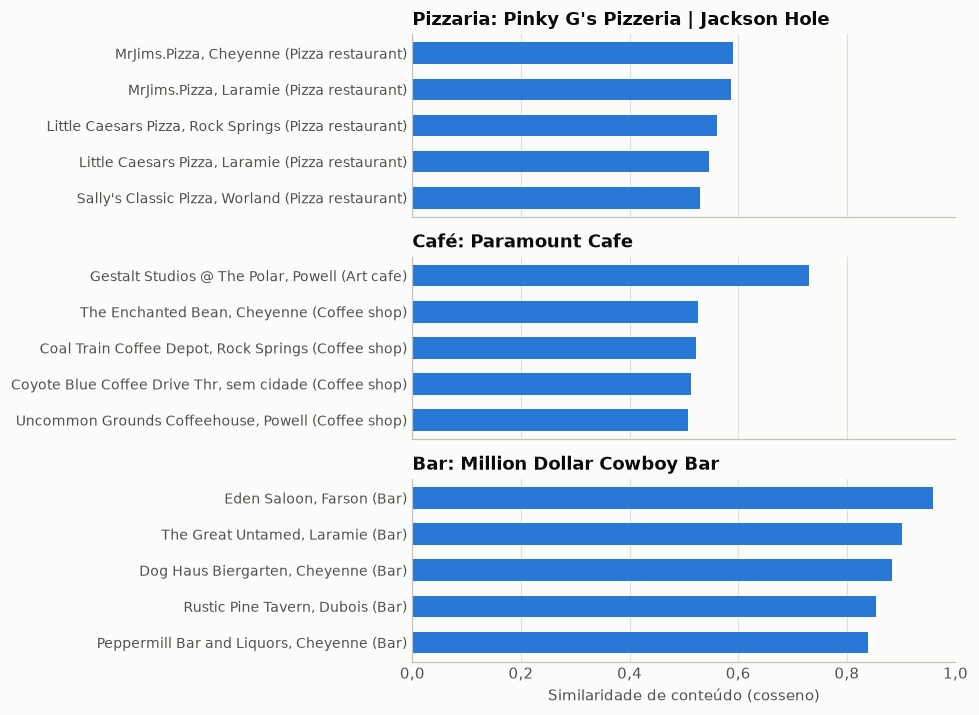

In [12]:
similaridades = (matriz @ matriz.T).toarray()
posicao = {gmap_id: i for i, gmap_id in enumerate(locais["gmap_id"])}
abertos = ~(locais["fechado_perm"] | locais["fechado_temp"]).to_numpy()


def vizinhos(gmap_id, quantidade=5):
    linha = similaridades[posicao[gmap_id]].copy()
    linha[posicao[gmap_id]] = -1
    linha[~abertos] = -1
    ordem = np.argsort(-linha, kind="stable")[:quantidade]
    return locais.iloc[ordem][["name", "cidade", "categoria_principal"]].assign(cosseno=linha[ordem].round(3)).reset_index(drop=True)


figura, eixos = plt.subplots(3, 1, figsize=(9, 6.6), sharex=True)
for eixo, (tipo, exemplo) in zip(eixos, exemplos.items()):
    tabela = vizinhos(exemplo["gmap_id"])
    print(f"{tipo}: {exemplo['name']}")
    display(tabela)
    rotulos = [
        f"{nome[:28].strip()}, {cidade if isinstance(cidade, str) else 'sem cidade'} ({categoria})".replace("$", "\\$")
        for nome, cidade, categoria in zip(tabela["name"], tabela["cidade"], tabela["categoria_principal"])
    ]
    # Posições numéricas: locais de mesmo nome não podem virar uma barra só.
    posicoes_barras = np.arange(len(tabela))[::-1]
    eixo.barh(posicoes_barras, tabela["cosseno"].values, color=COR_PRINCIPAL, height=0.6)
    eixo.set_yticks(posicoes_barras, rotulos)
    eixo.set_title(f"{tipo}: {exemplo['name']}".replace("$", "\\$"))
    eixo.set_xlim(0, 1)
    eixo.grid(axis="y", visible=False)
    eixo.tick_params(axis="y", labelsize=9)
    eixo_br(eixo.xaxis, 1)
eixos[-1].set_xlabel("Similaridade de conteúdo (cosseno)")
figura.tight_layout()
salvar(figura, "20_vizinhos_conteudo")
plt.show()

In [13]:
def medir_vizinhanca(matriz_avaliada, quantidade=5):
    sims = (matriz_avaliada @ matriz_avaliada.T).toarray()
    np.fill_diagonal(sims, -1)
    sims[:, ~abertos] = -1
    principal = locais["categoria_principal"].to_numpy()
    categorias = [set(lista) for lista in locais["category"]]
    com_vetor = np.flatnonzero(np.asarray(matriz_avaliada.sum(axis=1)).ravel() > 0)
    mesma, alguma = [], []
    for i in com_vetor:
        ordem = np.argpartition(-sims[i], quantidade)[:quantidade]
        mesma.append((principal[ordem] == principal[i]).mean())
        alguma.append(np.mean([bool(categorias[i] & categorias[j]) for j in ordem]))
    return np.mean(mesma), np.mean(alguma)


so_categorias = VetorizadorConteudo(peso_atributos=0).fit(locais_treino).transform(locais)
gerador_acaso = np.random.default_rng(42)
principal = locais["categoria_principal"].to_numpy()
sorteios = gerador_acaso.integers(len(locais), size=(len(locais), 5))
mesma_ao_acaso = (principal[sorteios] == principal[:, None]).mean()
resultado = pd.DataFrame(
    [medir_vizinhanca(matriz), medir_vizinhanca(so_categorias)],
    columns=["5 vizinhos com a mesma categoria principal", "5 vizinhos com alguma categoria em comum"],
    index=["Categorias + atributos", "Só categorias"],
).round(3)
print(f"Mesma categoria principal em locais sorteados ao acaso: {str(round(mesma_ao_acaso, 3)).replace('.', ',')}")
resultado

Mesma categoria principal em locais sorteados ao acaso: 0,057


,5 vizinhos com a mesma categoria principal,5 vizinhos com alguma categoria em comum
Categorias + atributos,0.797,0.981
Só categorias,0.779,0.994


**Sanidade do conteúdo:** os vizinhos dos três exemplos são do mesmo tipo. Em todo o catálogo, 79,7% dos 5 vizinhos têm a mesma categoria principal do local, contra 5,7% ao acaso, e 98,1% têm alguma categoria em comum. Usar só categorias dá valores parecidos (77,9% e 99,4%), então os atributos reduzidos **não pioraram** a vizinhança, e não há o que investigar.

**O que esses vizinhos não mostram:** o cosseno mede semelhança de tipo, não de qualidade nem de gosto. O Million Dollar Cowboy Bar fica a 0,959 de um bar de Farson porque os dois têm a categoria Bar e atributos parecidos. Essa é uma limitação conhecida do conteúdo, que os escores de produto ajudam a compensar.

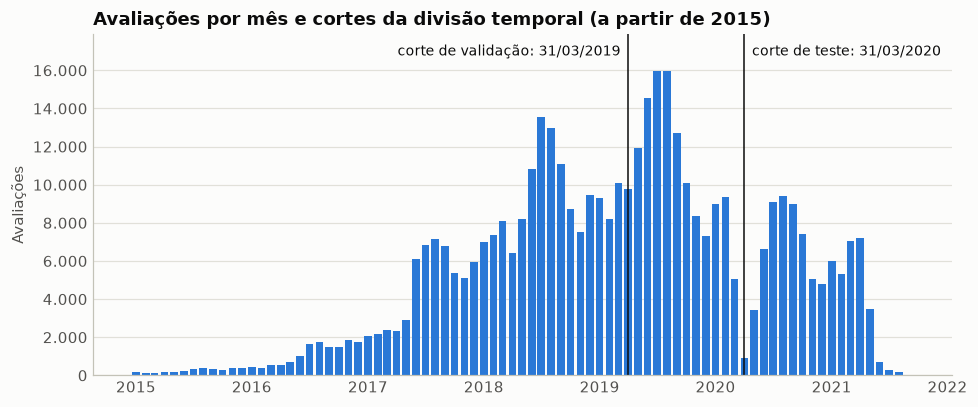

In [14]:
por_mes_total = avaliacoes.groupby(avaliacoes["data"].dt.to_period("M")).size()
por_mes_total = por_mes_total[por_mes_total.index >= pd.Period("2015-01")]

figura, eixo = plt.subplots(figsize=(9, 3.8))
eixo.bar(por_mes_total.index.to_timestamp(), por_mes_total.values, width=24, color=COR_PRINCIPAL)
for corte, rotulo, deslocamento, alinhamento in [
    (corte_validacao, "corte de validação", -5, "right"),
    (corte_teste, "corte de teste", 5, "left"),
]:
    eixo.axvline(corte, color=COR_TEXTO, linewidth=1)
    eixo.annotate(f"{rotulo}: {corte:%d/%m/%Y}", (corte, por_mes_total.max() * 1.05), xytext=(deslocamento, 0), textcoords="offset points", ha=alinhamento, fontsize=9)
eixo.set_ylim(0, por_mes_total.max() * 1.12)
eixo.set_title("Avaliações por mês e cortes da divisão temporal (a partir de 2015)")
eixo.set_ylabel("Avaliações")
eixo.grid(axis="x", visible=False)
eixo_br(eixo.yaxis)
figura.tight_layout()
salvar(figura, "21_divisao_temporal")
plt.show()

**Linha do tempo:** a validação cobre um ano inteiro, incluindo o pico de verão de 2019, e termina na queda de março de 2020. O teste começa no ponto mais baixo da pandemia e se esvazia no fim da coleta, como descrito na seção 2.2.

In [15]:
novos_tabela = conjuntos["locais_novos"]


def locais_de(origem, conjunto):
    return set(novos_tabela.loc[(novos_tabela["origem"] == origem) & (novos_tabela["conjunto"] == conjunto), "gmap_id"])


s_val, s_teste = locais_de("simulado", "validacao"), locais_de("simulado", "teste")
treino_c, treino_total_c = conjuntos["treino"], conjuntos["treino_total"]
fechados_ids = set(locais.loc[locais["fechado_perm"] | locais["fechado_temp"], "gmap_id"])
indice_gravado = pd.read_parquet(PASTA_CONJUNTOS / "indice_locais.parquet")
repeticao = montar_conjuntos(avaliacoes, locais)

verificacoes = {
    "Datas sem sobreposição": treino_c["data"].max() < validacao_c["data"].min() and validacao_c["data"].max() < teste_c["data"].min(),
    "Contagens fecham": len(treino_c) + len(validacao_c) == len(treino_total_c) and len(treino_total_c) + len(teste_c) == len(avaliacoes),
    "S_val fora do treino dele": not s_val & set(conjuntos["treino_c3"]["gmap_id"]),
    "S_teste fora do treino dele": not s_teste & set(conjuntos["treino_total_c3"]["gmap_id"]),
    "S_val e S_teste disjuntos": not s_val & s_teste,
    "100 locais em cada simulado": len(s_val) == 100 and len(s_teste) == 100,
    "Simulado com 20 ou mais avaliações no treino dele": treino_c[treino_c["gmap_id"].isin(s_val)].groupby("gmap_id").size().min() >= 20
    and treino_total_c[treino_total_c["gmap_id"].isin(s_teste)].groupby("gmap_id").size().min() >= 20,
    "Nenhum simulado fechado": not (s_val | s_teste) & fechados_ids,
    "Usuário novo fora do treino (validação)": not set(validacao_c.loc[validacao_c["segmento"] == "novo", "user_id"]) & set(treino_c["user_id"]),
    "Usuário novo fora do treino (teste)": not set(teste_c.loc[teste_c["segmento"] == "novo", "user_id"]) & set(treino_total_c["user_id"]),
    "Antigo com 3 ou mais avaliações": validacao_c.loc[validacao_c["segmento"] == "antigo", "avaliacoes_no_treino"].min() >= 3
    and teste_c.loc[teste_c["segmento"] == "antigo", "avaliacoes_no_treino"].min() >= 3,
    "Local novo natural fora do treino (validação)": not locais_de("natural", "validacao") & set(treino_c["gmap_id"]),
    "Local novo natural fora do treino (teste)": not locais_de("natural", "teste") & set(treino_total_c["gmap_id"]),
    "Todo local com linha na matriz": indice_gravado["gmap_id"].tolist() == locais["gmap_id"].tolist() and len(indice_gravado) == matriz.shape[0],
    "Toda avaliação com local no índice": set(avaliacoes["gmap_id"]) <= set(indice_gravado["gmap_id"]),
    "Divisão reproduzível": all(repeticao[nome].equals(conjuntos[nome]) for nome in conjuntos),
    "Arquivos gravados iguais aos da memória": all(
        pd.read_parquet(PASTA_CONJUNTOS / f"{nome}.parquet").equals(conjuntos[nome].reset_index(drop=True)) for nome in conjuntos
    ),
}
print(f"Verificações aprovadas: {sum(map(bool, verificacoes.values()))} de {len(verificacoes)}")
assert all(verificacoes.values()), [nome for nome, passou in verificacoes.items() if not passou]
pd.Series(verificacoes, name="passou").to_frame()

Verificações aprovadas: 17 de 17


,passou
Datas sem sobreposição,True
Contagens fecham,True
S_val fora do treino dele,True
S_teste fora do treino dele,True
S_val e S_teste disjuntos,True
100 locais em cada simulado,True
Simulado com 20 ou mais avaliações no treino dele,True
Nenhum simulado fechado,True
Usuário novo fora do treino (validação),True
Usuário novo fora do treino (teste),True


**Conclusão da Fase 2:** as 17 verificações passaram, e os testes à mão da divisão estão em `testes/test_divisao.py`. Os vetores fazem sentido, a divisão é reproduzível e nada foi medido no teste. A Fase 3 pode começar.